# 04 - Responders vs non-responders
All statistics treat the **patient** as the unit of replication (6 responders, 7 non-responders), never the cell: thousands of cells from one patient are not independent observations.

1. Baseline (pre-ACT) immune-cell composition, responders vs non-responders
2. Pre- vs post-ACT change in composition (paired, descriptive only: n is too small to test)
3. Pre-specified signature scores for the findings reported in the source paper (CD8 cytotoxicity/exhaustion/costimulation; myeloid type I interferon)
4. Unbiased pseudobulk differential expression (PyDESeq2) in CD8 T cells and macrophages/monocytes

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
sc.settings.set_figure_params(dpi=100, frameon=False)
FIG, TAB = "../results/figures/", "../results/tables/"
PAL = {"R": "#1b9e77", "NR": "#d95f02"}

ann = sc.read_h5ad("../data/processed/cd45_annotated.h5ad", backed="r").obs[["cell_type", "lineage"]]
adata = sc.read_h5ad("../data/processed/cd45_qc.h5ad")          # full gene set, raw counts in .X / layers['counts']
adata.obs = adata.obs.join(ann)
adata.obs["patient"] = adata.obs["patient"].astype(str)
print(adata.n_obs, "cells,", adata.n_vars, "genes")

87486 cells, 23266 genes


## 0. Which cells and libraries are analysed
- Immune lineages only (T/NK, myeloid, B/plasma): the post-ACT libraries contain many non-immune cells, which would distort proportions.
- Drop three clusters that are too small or too ambiguous to analyse (inflammatory myeloid, n=11; CD8 GZMK+ HAVCR2+, n=51; low-quality lymphocytes are already outside the immune lineages).
- Require >= 200 immune cells per library.

In [2]:
EXCLUDE = {"Inflammatory myeloid (tiny)", "CD8 T (GZMK+ HAVCR2+, small)"}
imm = adata[adata.obs.lineage.isin(["T/NK", "Myeloid", "B/plasma"]) & ~adata.obs.cell_type.isin(EXCLUDE)].copy()
imm.obs["cell_type"] = imm.obs["cell_type"].cat.remove_unused_categories()
lib = imm.obs.groupby("sample", observed=True).agg(patient=("patient", "first"), timepoint=("timepoint", "first"),
                                                    response=("response", "first"), immune_cells=("sample", "size"))
lib["kept"] = lib.immune_cells >= 200
print("Excluded libraries (<200 immune cells):", lib.index[~lib.kept].tolist())
imm = imm[imm.obs["sample"].isin(lib.index[lib.kept])].copy()
imm.obs["sample"] = imm.obs["sample"].astype(str)
print(imm.n_obs, "immune cells analysed")
lib.sort_values(["timepoint", "patient"])

Excluded libraries (<200 immune cells): ['patient5_T30']


74815 immune cells analysed


,patient,timepoint,response,immune_cells,kept
sample,,,,,
patient1_T30,1,post,NR,3666,True
patient10_T30,10,post,NR,2148,True
patient13_T30,13,post,R,4094,True
patient5_T30,5,post,NR,120,False
patient6_T30,6,post,NR,2097,True
patient7_T30,7,post,R,1377,True
patient8_T30,8,post,R,4962,True
patient1_T0,1,pre,NR,4571,True
patient10_T01,10,pre,NR,7474,True


## 1. Baseline composition (pre-ACT), one value per patient

In [3]:
pre = imm[imm.obs.timepoint == "pre"]
cnt = pd.crosstab(pre.obs.patient, pre.obs.cell_type)           # biopsy sites pooled within patient
prop = cnt.div(cnt.sum(1), axis=0) * 100
resp = pre.obs.groupby("patient").response.first().astype(str)
rows = []
for ct in prop.columns:
    r, nr = prop.loc[resp[resp == "R"].index, ct], prop.loc[resp[resp == "NR"].index, ct]
    rows.append((ct, r.median(), nr.median(), mannwhitneyu(r, nr).pvalue))
comp = pd.DataFrame(rows, columns=["cell_type", "median_%_R", "median_%_NR", "p"]).set_index("cell_type")
comp["fdr"] = multipletests(comp.p, method="fdr_bh")[1]
comp = comp.sort_values("p"); comp.round(3).to_csv(TAB + "composition_R_vs_NR_baseline.csv")
print(f"{len(resp)} patients: R={sum(resp=='R')}, NR={sum(resp=='NR')};  min FDR = {comp.fdr.min():.3f}")
comp.round(3)

13 patients: R=6, NR=7;  min FDR = 0.732


,median_%_R,median_%_NR,p,fdr
cell_type,,,,
Regulatory T cell,8.833,6.060,0.073,0.732
Proliferating T cell,3.090,1.085,0.138,0.732
Mature DC (LAMP3+ CCR7+),0.022,0.241,0.222,0.732
Macrophage (C1Q+),2.389,29.498,0.234,0.732
Plasmacytoid DC,0.456,0.766,0.234,0.732
"CD4 T (CXCL13+ PD-1+, Tph-like)",2.512,1.017,0.295,0.732
Classical monocyte,0.848,1.225,0.366,0.732
"CD8 T (cytotoxic, exhausted-like)",25.836,6.366,0.366,0.732
NK cell,0.188,0.383,0.445,0.792


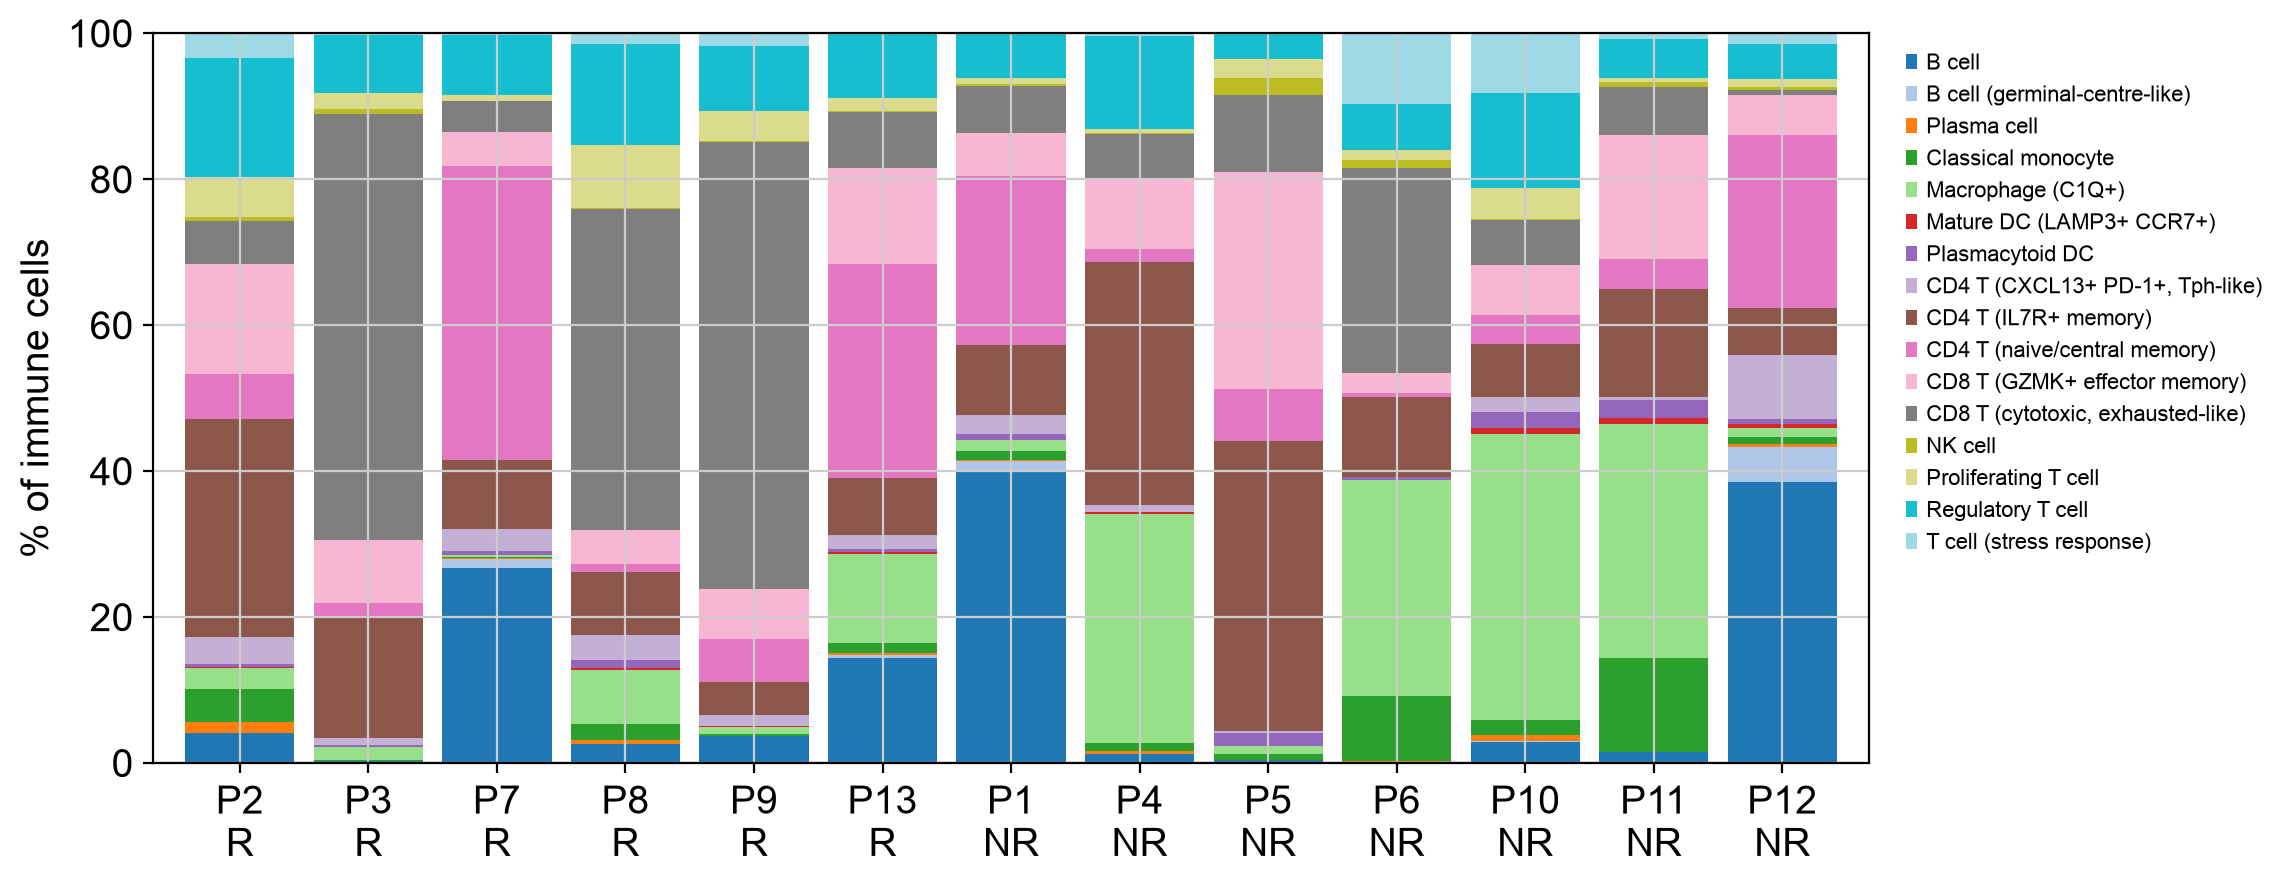

In [4]:
order = resp.sort_values().index.tolist()[::-1]               # R first
order = sorted(order, key=lambda p: (resp[p] != "R", int(p)))
fig, ax = plt.subplots(figsize=(11, 4.8))
prop.loc[order].plot.bar(stacked=True, ax=ax, width=0.85, colormap="tab20", legend=False)
ax.set_xticklabels([f"P{p}\n{resp[p]}" for p in order], rotation=0); ax.set_ylabel("% of immune cells"); ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=8)
plt.savefig(FIG + "04_composition_by_patient.png", dpi=150, bbox_inches="tight")

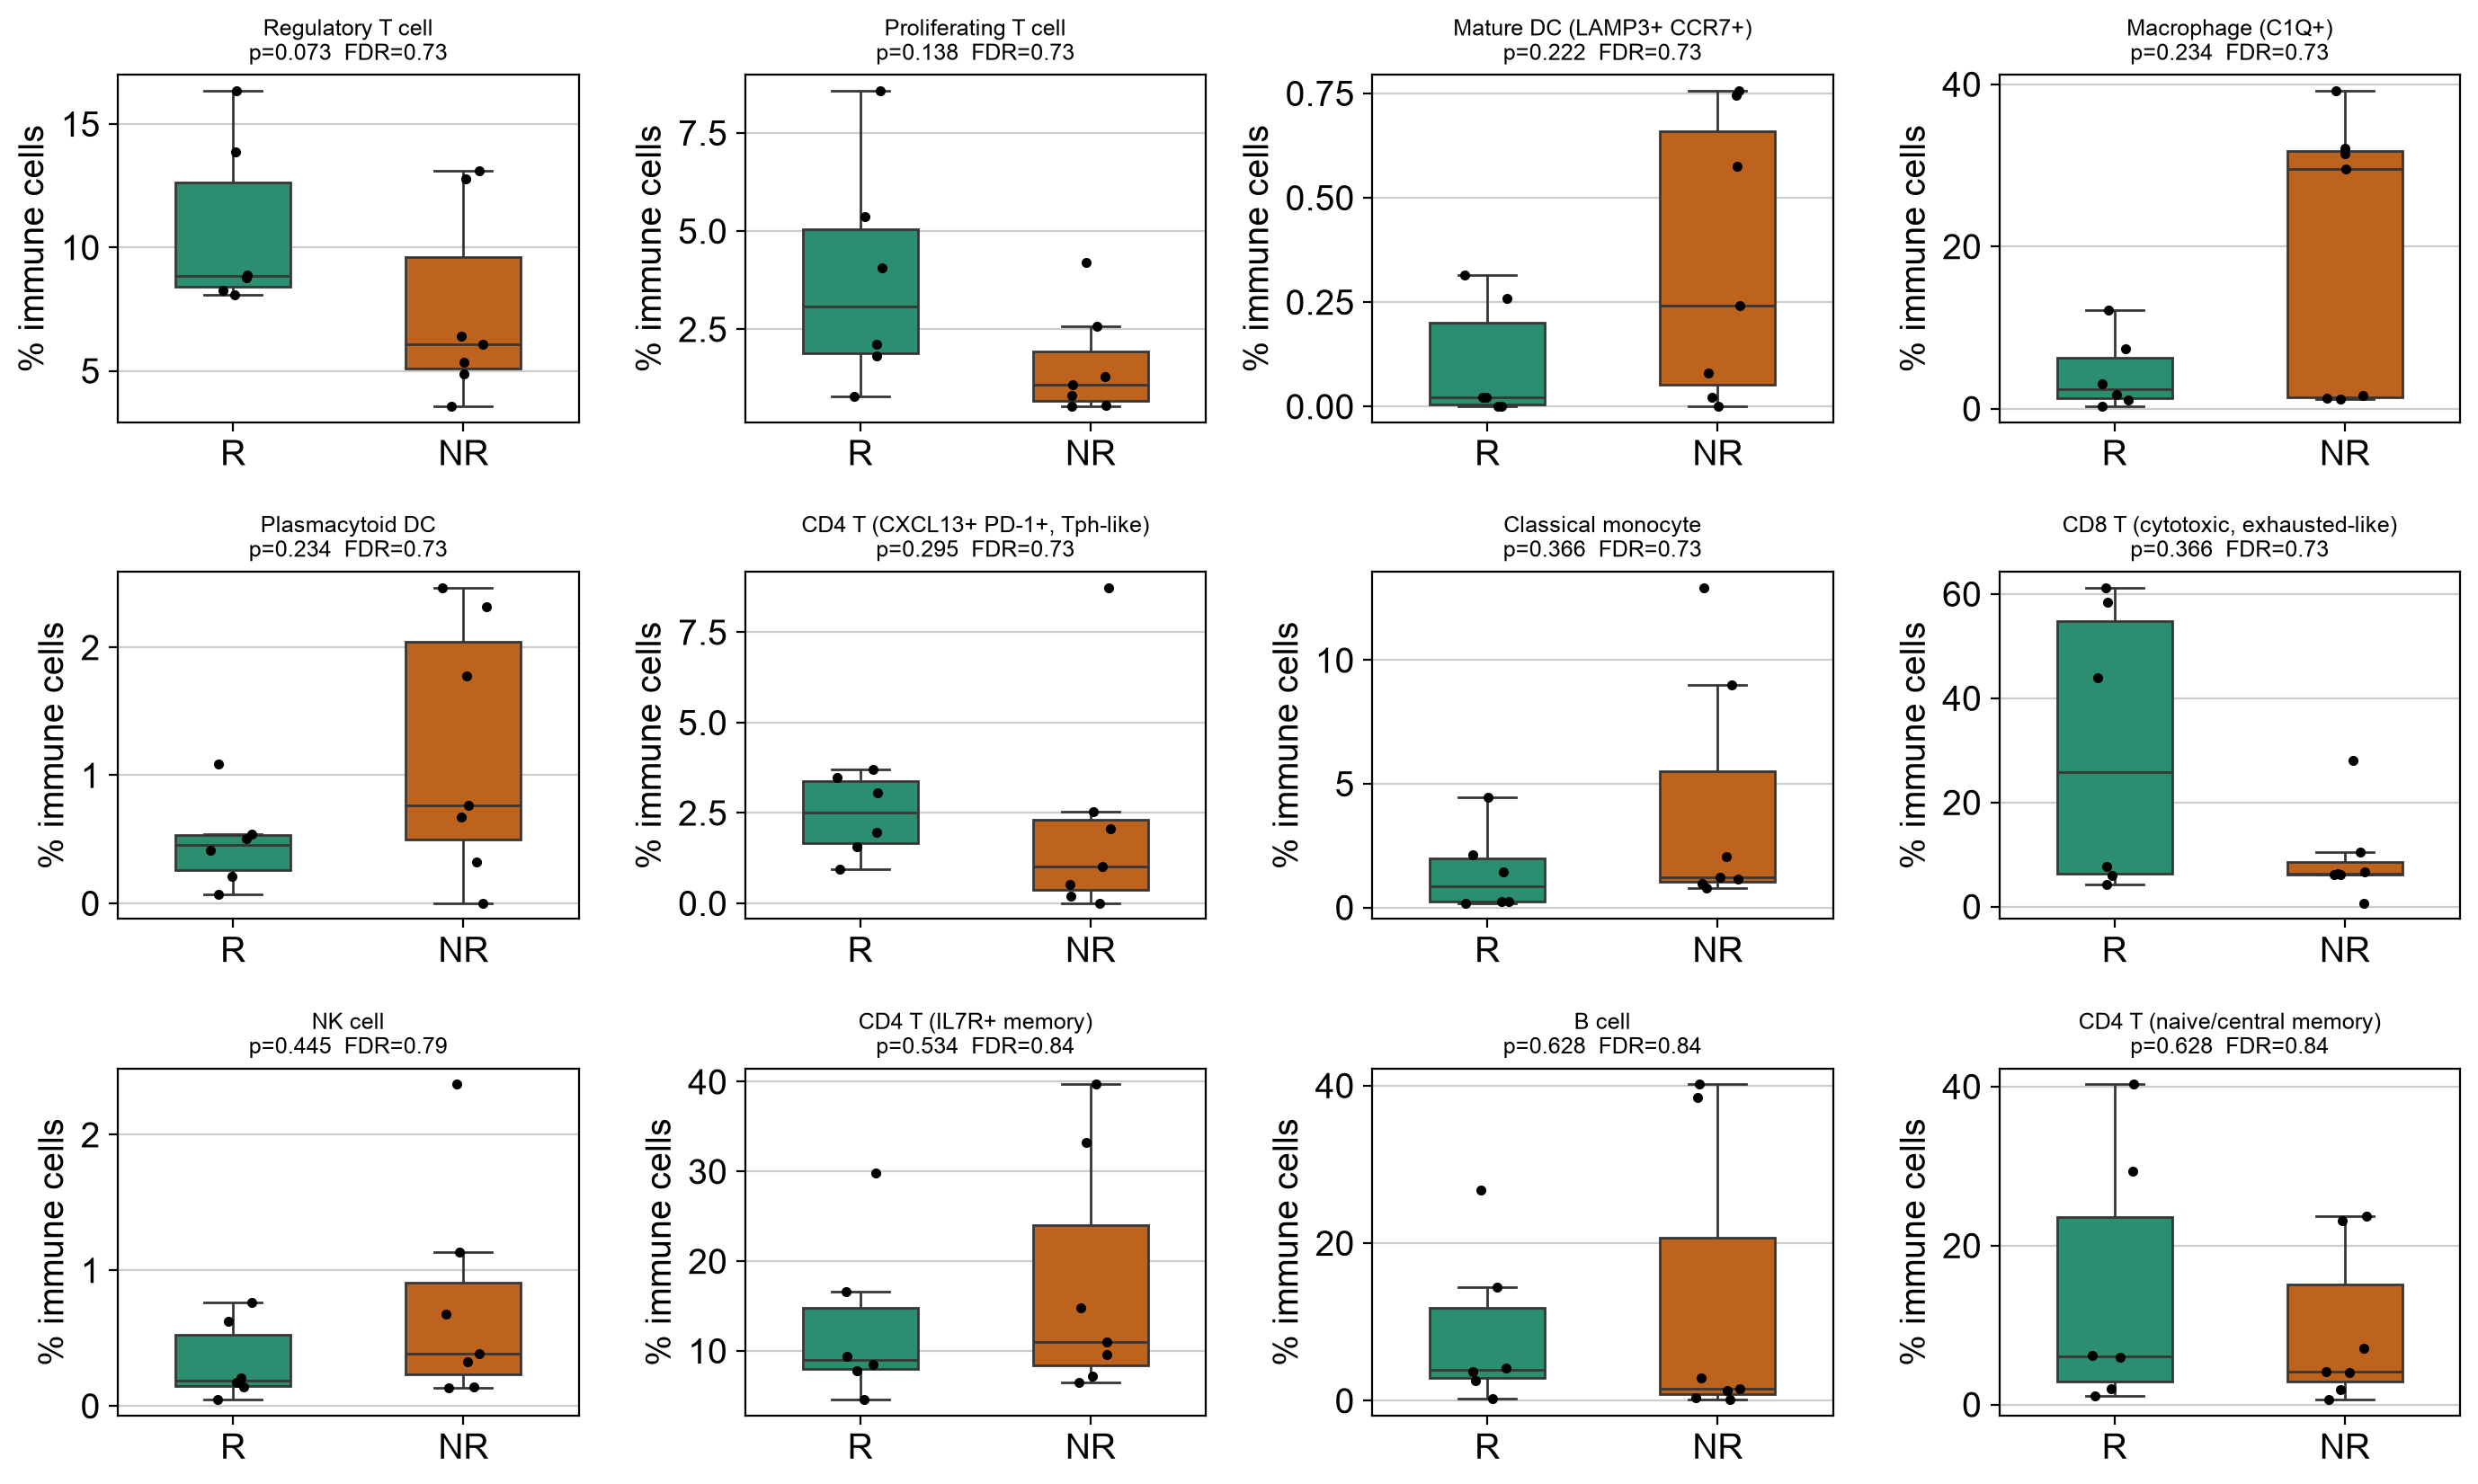

In [5]:
top = comp.index[:12]
fig, axes = plt.subplots(3, 4, figsize=(14, 8.5)); 
for ax, ct in zip(axes.ravel(), top):
    d = pd.DataFrame({"pct": prop[ct], "response": resp})
    sns.boxplot(data=d, x="response", y="pct", order=["R", "NR"], palette=PAL, ax=ax, showfliers=False, width=0.5)
    sns.stripplot(data=d, x="response", y="pct", order=["R", "NR"], color="k", size=4, ax=ax)
    ax.set_title(f"{ct}\np={comp.loc[ct,'p']:.3f}  FDR={comp.loc[ct,'fdr']:.2f}", fontsize=9); ax.set_xlabel(""); ax.set_ylabel("% immune cells")
plt.tight_layout(); plt.savefig(FIG + "04_composition_R_vs_NR_top12.png", dpi=150, bbox_inches="tight")

## 2. Pre- vs post-ACT, paired within patient (descriptive)
Only six patients have a usable post-ACT library, so no formal test is run: with n=6 the smallest attainable two-sided p-value (0.031) cannot survive correction across ~17 cell types.

In [6]:
post = imm[imm.obs.timepoint == "post"]
cp = pd.crosstab(post.obs.patient, post.obs.cell_type); pp = cp.div(cp.sum(1), axis=0) * 100
paired = sorted(set(pp.index) & set(prop.index), key=int)
delta = (pp.loc[paired] - prop.loc[paired]).T
delta.columns = [f"P{p} ({resp[p]})" for p in paired]
delta["mean_change_R"] = delta[[c for c in delta.columns if "(R)" in c]].mean(1)
delta["mean_change_NR"] = delta[[c for c in delta.columns if "(NR)" in c]].mean(1)
delta.round(1).to_csv(TAB + "composition_change_post_minus_pre.csv")
print("Patients with paired data:", paired)
delta.loc[delta.drop(columns=["mean_change_R", "mean_change_NR"]).abs().mean(1).sort_values(ascending=False).index].round(1).head(10)

Patients with paired data: ['1', '6', '7', '8', '10', '13']


,P1 (NR),P6 (NR),P7 (R),P8 (R),P10 (NR),P13 (R),mean_change_R,mean_change_NR
cell_type,,,,,,,,
"CD8 T (cytotoxic, exhausted-like)",16.5,-19.4,3.2,-31.5,4.8,69.8,13.8,0.6
CD8 T (GZMK+ effector memory),30.6,4.7,18.4,10.9,36.1,-5.5,7.9,23.8
CD4 T (naive/central memory),-22.4,-0.3,-37.3,0.4,-3.4,-29.1,-22.0,-8.7
Macrophage (C1Q+),1.8,-21.4,8.7,7.0,-32.8,-11.5,1.4,-17.5
B cell,-40.2,-0.1,-25.4,-0.4,-2.7,-14.3,-13.3,-14.3
CD4 T (IL7R+ memory),6.8,19.0,20.7,-0.9,14.6,0.7,6.8,13.5
Classical monocyte,9.7,3.8,5.8,12.2,0.4,0.0,6.0,4.6
T cell (stress response),2.9,13.9,-0.1,-1.3,-8.2,-0.0,-0.5,2.9
Regulatory T cell,-2.8,-3.0,0.5,1.1,-5.3,-8.1,-2.2,-3.7


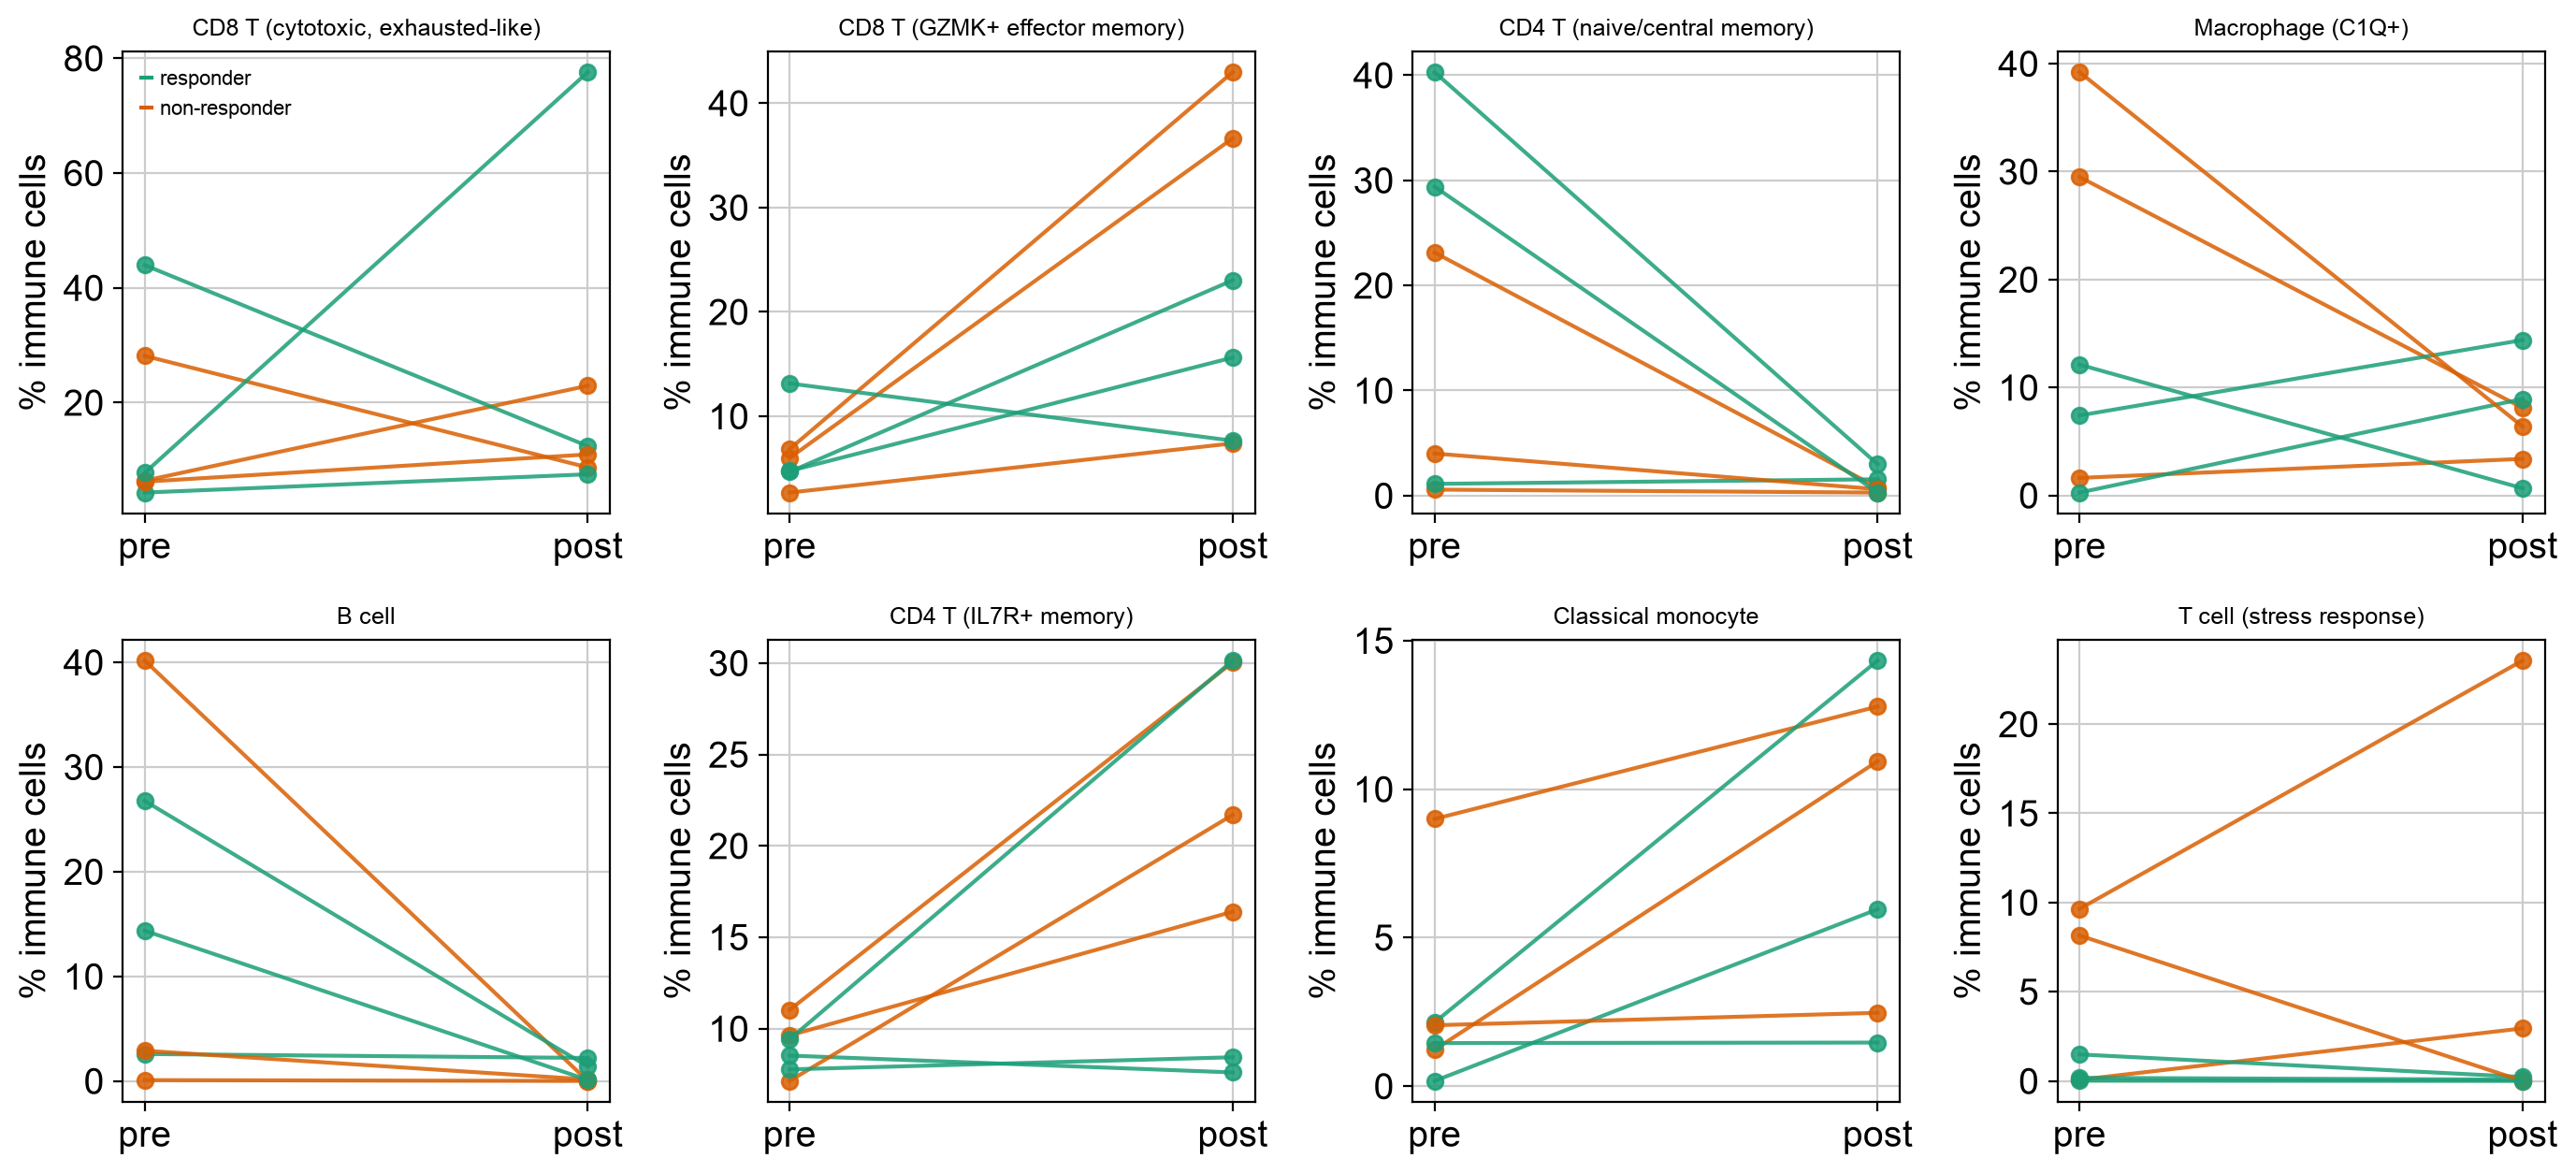

In [7]:
sel = delta.drop(columns=["mean_change_R", "mean_change_NR"]).abs().mean(1).sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, ct in zip(axes.ravel(), sel):
    for p in paired:
        ax.plot(["pre", "post"], [prop.loc[p, ct], pp.loc[p, ct]], "-o", color=PAL[resp[p]], alpha=0.85)
    ax.set_title(ct, fontsize=9); ax.set_ylabel("% immune cells")
axes[0, 0].plot([], [], color=PAL["R"], label="responder"); axes[0, 0].plot([], [], color=PAL["NR"], label="non-responder"); axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "04_paired_pre_post.png", dpi=150, bbox_inches="tight")

## 3. Pre-specified signatures at baseline
The source paper reports, for responders: CD8 T cells with higher cytotoxicity, exhaustion and costimulation; myeloid cells with stronger type I interferon signalling. The gene sets below were written down **before** looking at these data (they are not tuned to this dataset), so this is a direct replication test of four stated hypotheses, FDR-corrected across the four tests.

In [8]:
SIG = {
 "CD8 cytotoxicity":     ["GZMA", "GZMB", "GZMH", "PRF1", "GNLY", "NKG7", "CST7", "CTSW", "KLRD1"],
 "CD8 exhaustion":       ["PDCD1", "LAG3", "HAVCR2", "TIGIT", "CTLA4", "TOX", "ENTPD1", "CXCL13"],
 "CD8 costimulation":    ["CD28", "ICOS", "TNFRSF9", "TNFRSF4", "TNFRSF18", "CD27", "CD226"],
 "Myeloid type I IFN":   ["ISG15", "IFIT1", "IFIT2", "IFIT3", "IFI6", "IFI44", "IFI44L", "MX1", "MX2", "OAS1", "OAS2", "OASL", "IRF7", "STAT1", "RSAD2"],
}
COMP = {"CD8": ["CD8 T (GZMK+ effector memory)", "CD8 T (cytotoxic, exhausted-like)"],
        "Myeloid": ["Macrophage (C1Q+)", "Classical monocyte"]}
sub = {k: pre[pre.obs.cell_type.isin(v)].copy() for k, v in COMP.items()}
for k, a in sub.items():
    sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a)
    print(k, a.n_obs, "cells; per-patient min:", a.obs.groupby("patient", observed=True).size().min())
res = []
for name, genes in SIG.items():
    k = "CD8" if name.startswith("CD8") else "Myeloid"; a = sub[k]
    g = [x for x in genes if x in a.var_names]
    sc.tl.score_genes(a, g, score_name="score", random_state=0)
    s = a.obs.groupby("patient", observed=True).score.mean()
    s = s[a.obs.groupby("patient", observed=True).size() >= 50]
    r, nr = s[resp[s.index] == "R"], s[resp[s.index] == "NR"]
    res.append((name, len(g), len(r), len(nr), r.median(), nr.median(), mannwhitneyu(r, nr).pvalue, s))
sig = pd.DataFrame([x[:7] for x in res], columns=["signature", "genes_used", "n_R", "n_NR", "median_R", "median_NR", "p"]).set_index("signature")
sig["fdr"] = multipletests(sig.p, method="fdr_bh")[1]; sig.round(3).to_csv(TAB + "signature_scores_R_vs_NR.csv"); sig.round(3)

CD8 15043 cells; per-patient min: 192
Myeloid 9606 cells; per-patient min: 10


,genes_used,n_R,n_NR,median_R,median_NR,p,fdr
signature,,,,,,,
CD8 cytotoxicity,9,6,7,0.721,0.595,0.534,0.534
CD8 exhaustion,8,6,7,-0.087,-0.447,0.073,0.135
CD8 costimulation,7,6,7,0.029,-0.118,0.101,0.135
Myeloid type I IFN,15,5,6,0.242,-0.023,0.052,0.135


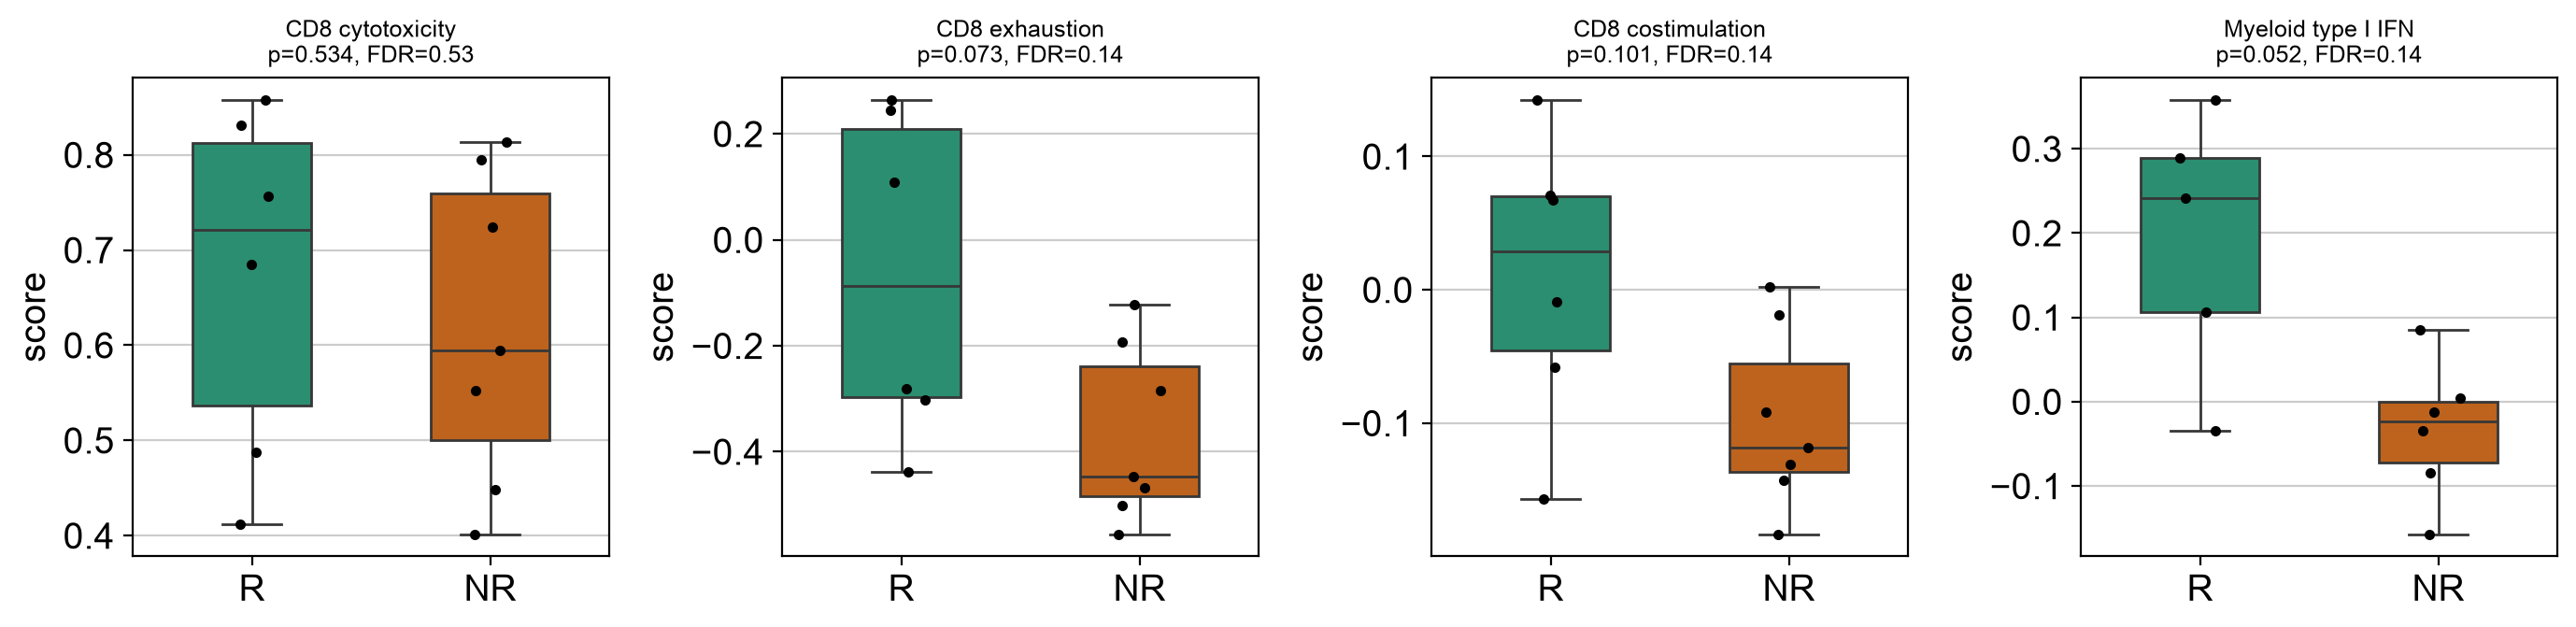

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (name, *_, s) in zip(axes, res):
    d = pd.DataFrame({"score": s, "response": resp[s.index]})
    sns.boxplot(data=d, x="response", y="score", order=["R", "NR"], palette=PAL, ax=ax, showfliers=False, width=0.5)
    sns.stripplot(data=d, x="response", y="score", order=["R", "NR"], color="k", size=4, ax=ax)
    ax.set_title(f"{name}\np={sig.loc[name,'p']:.3f}, FDR={sig.loc[name,'fdr']:.2f}", fontsize=9); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG + "04_signatures_R_vs_NR.png", dpi=150, bbox_inches="tight")

## 4. Unbiased pseudobulk differential expression
Counts are summed per patient within a cell compartment, then modelled with PyDESeq2 (`~ response`). Patients with fewer than 50 cells in the compartment are dropped.

In [10]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
def pseudobulk_de(a, label, min_cells=50):
    n = a.obs.groupby("patient", observed=True).size(); keep = n[n >= min_cells].index.tolist()
    X = a.layers["counts"] if "counts" in a.layers else a.X
    mats = {p: np.asarray(X[(a.obs.patient == p).values].sum(0)).ravel() for p in keep}
    counts = pd.DataFrame(mats, index=a.var_names).T.round().astype(int)
    counts = counts.loc[:, (counts >= 10).sum(0) >= 4]
    meta = pd.DataFrame({"response": resp[keep].astype(str)}, index=keep)
    dds = DeseqDataSet(counts=counts, metadata=meta, design="~response", ref_level=["response", "NR"], quiet=True)
    dds.deseq2()
    ds = DeseqStats(dds, contrast=["response", "R", "NR"], quiet=True); ds.summary()
    r = ds.results_df.dropna(subset=["padj"]).sort_values("pvalue")
    r.to_csv(TAB + f"pseudobulk_DE_{label}.csv")
    print(f"{label}: {len(keep)} patients (R={int((meta.response=='R').sum())}, NR={int((meta.response=='NR').sum())}), {counts.shape[1]} genes tested, "
          f"FDR<0.1: {(r.padj<0.1).sum()} ({(r[r.padj<0.1].log2FoldChange>0).sum()} up in R)")
    return r
de = {k: pseudobulk_de(sub[k], k) for k in ("CD8", "Myeloid")}

CD8: 13 patients (R=6, NR=7), 10832 genes tested, FDR<0.1: 17 (7 up in R)


Myeloid: 11 patients (R=5, NR=6), 11780 genes tested, FDR<0.1: 20 (20 up in R)


In [11]:
for k, r in de.items():
    print(f"\n=== {k}: top genes higher in responders ==="); print(r[r.log2FoldChange > 0].head(10)[["baseMean", "log2FoldChange", "pvalue", "padj"]].round(4).to_string())
    print(f"=== {k}: top genes higher in non-responders ==="); print(r[r.log2FoldChange < 0].head(10)[["baseMean", "log2FoldChange", "pvalue", "padj"]].round(4).to_string())


=== CD8: top genes higher in responders ===
           baseMean  log2FoldChange  pvalue    padj
SH3BGRL2    12.0719          3.2762  0.0000  0.0018
LINC01480   49.5595          2.3040  0.0000  0.0147
HIPK2       40.1726          1.6252  0.0000  0.0147
CD80        10.6861          2.5417  0.0000  0.0177
BTLA        42.3074          1.1796  0.0000  0.0641
TSHZ2       28.9325          2.3585  0.0001  0.0860
CLIP3        7.5695          2.3615  0.0001  0.0860
ETV1        54.2402          2.0273  0.0003  0.1647
CD200       57.6500          2.0366  0.0003  0.1707
WARS       141.9940          0.9634  0.0004  0.1717
=== CD8: top genes higher in non-responders ===
         baseMean  log2FoldChange  pvalue    padj
TRDC      56.7985         -2.0771  0.0000  0.0147
EBPL       9.6114         -2.3823  0.0000  0.0147
SWAP70    14.1912         -1.5606  0.0000  0.0160
SLC39A8   47.3427         -0.9555  0.0001  0.0822
CARNMT1   35.0072         -0.9930  0.0001  0.0822
GALNT3    17.5307         -1.6074  

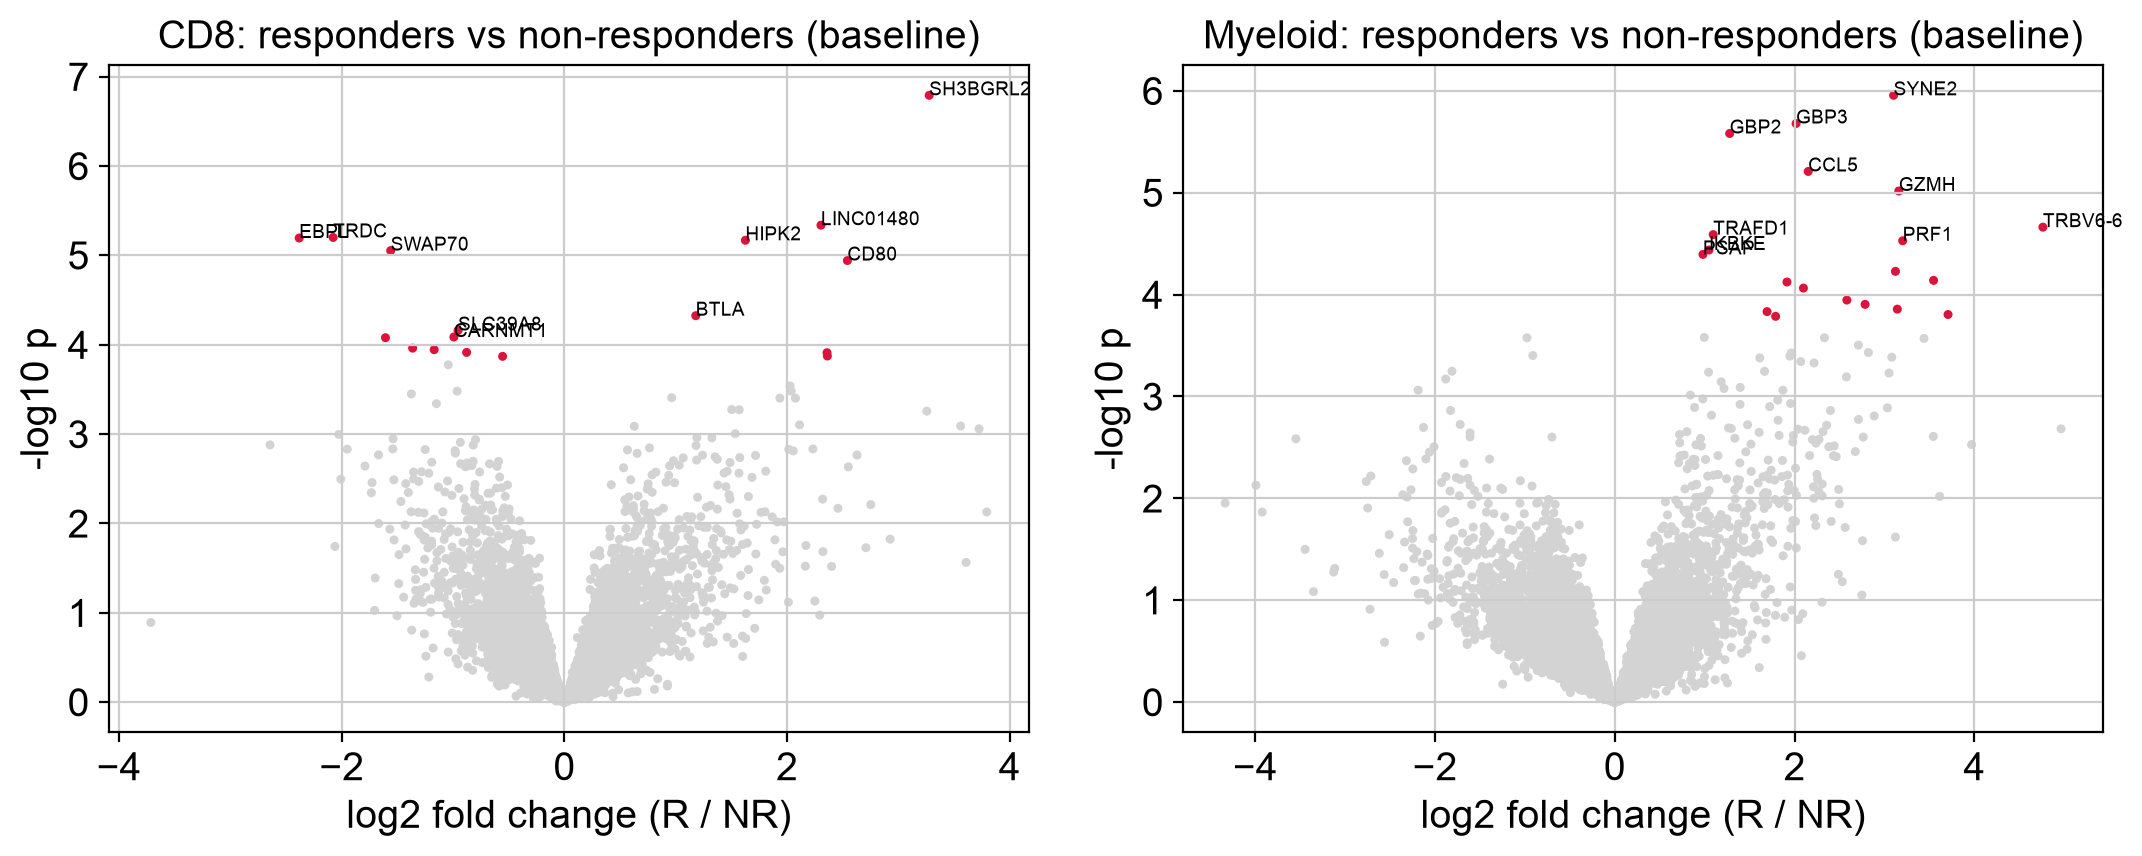

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (k, r) in zip(axes, de.items()):
    ax.scatter(r.log2FoldChange, -np.log10(r.pvalue), s=5, c=np.where(r.padj < 0.1, "crimson", "lightgrey"))
    for g in r.head(10).index: ax.annotate(g, (r.loc[g, "log2FoldChange"], -np.log10(r.loc[g, "pvalue"])), fontsize=7)
    ax.set_title(f"{k}: responders vs non-responders (baseline)"); ax.set_xlabel("log2 fold change (R / NR)"); ax.set_ylabel("-log10 p")
plt.tight_layout(); plt.savefig(FIG + "04_pseudobulk_volcanoes.png", dpi=150, bbox_inches="tight")

## 5. Confounder check: T-cell RNA inside myeloid cells
Several genes called "higher in responders" in myeloid cells are T/NK genes (CCL5, GZMH, PRF1, CD8A, TRBV*). Responders are T-cell-rich, so ambient RNA or doublets could inject T-cell transcripts into myeloid cells in proportion to how many T cells the tumor contains. Test: a T-cell gene score computed inside myeloid cells only.

In [13]:
TC = [g for g in ["CD3D", "CD3E", "CD2", "TRAC", "TRBC1", "TRBC2", "CCL5", "NKG7", "GZMH", "PRF1"] if g in sub["Myeloid"].var_names]
m = sub["Myeloid"]; m.obs["tcell_in_myeloid"] = np.asarray(m[:, TC].X.mean(1)).ravel()
g = m.obs.groupby("patient", observed=True).agg(cells=("tcell_in_myeloid", "size"), mean_score=("tcell_in_myeloid", "mean")); g = g[g.cells >= 50]
g["response"] = resp[g.index]
R_, NR_ = g[g.response == "R"].mean_score, g[g.response == "NR"].mean_score
print(f"T-cell gene score in myeloid cells: R median {R_.median():.3f} vs NR median {NR_.median():.3f}, Mann-Whitney p={mannwhitneyu(R_, NR_).pvalue:.4f}")
tcell_like = [x for x in de["Myeloid"][de["Myeloid"].padj < 0.1].index if x.startswith("TRB") or x in TC or x in ("CD8A", "ITM2A")]
print("T/NK genes among myeloid hits (FDR<0.1):", tcell_like)
g.sort_values("mean_score").round(3)

T-cell gene score in myeloid cells: R median 0.210 vs NR median 0.062, Mann-Whitney p=0.0043
T/NK genes among myeloid hits (FDR<0.1): ['CCL5', 'GZMH', 'TRBV6-6', 'PRF1', 'ITM2A', 'CD8A', 'TRBV27', 'TRBV7-6']


,cells,mean_score,response
patient,,,
6,475,0.028,NR
11,1130,0.054,NR
10,4813,0.061,NR
12,69,0.064,NR
4,1217,0.072,NR
1,130,0.096,NR
13,889,0.108,R
2,357,0.116,R
8,334,0.210,R


**Reading of section 5.** The myeloid pseudobulk result is confounded by T-cell RNA contamination and should not be interpreted as myeloid biology. A valid test needs ambient-RNA removal (e.g. SoupX, DecontX or CellBender) before pseudobulking. The interferon-inducible genes in the list (GBP1-4, LGALS3BP) are consistent with the paper's type I interferon finding but cannot be separated from this artifact here.